[0.1688, 0.3647, 0.3091, 0.1289, 0.0263, 0.0022]


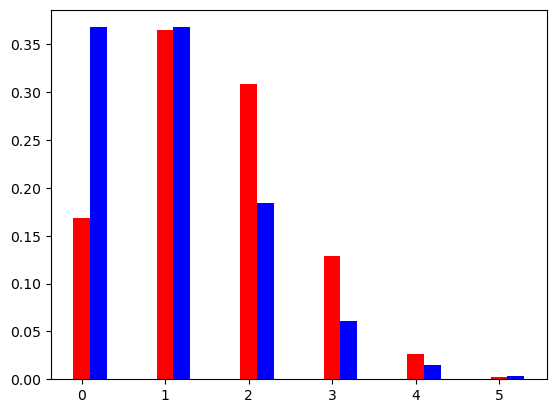

In [4]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
import random as rd
import math
def combinaison(n, k):
  if n == 0:
    return 0
  elif k == 0 or k == n:
    return 1
  else:
    return combinaison(n - 1, k - 1) + combinaison(n - 1, k)
def binomialev2(n, p):
  u = rd.random()
  i = -1
  c = 0
  while u >= c:
    i += 1
    c += combinaison(n, i) * p ** i * (1 - p) ** (n - i)
  return i  

def main():
  N=10000
  p=0.3
  n=5
  P = [math.exp(-1)/math.factorial(k) for k in range(0,n+1)]   
  valeurs = [binomialev2(n, p) for _ in range(N)]
  XX= [valeurs.count(i)/N for i in range(0,n+1)]
  print(XX)
  absc = np.linspace(0, n,n+1)
  plt.bar(absc, XX, color = 'r', width = 0.2)
  plt.bar(absc + 0.2, P, color = 'b', width = 0.2)
main()  

## Algorithme 1 : comparaison des probabilités théoriques

In [1]:
import numpy as np
from scipy.stats import binom, poisson
n=1000
p=0.003
lam=n*p
for k in range(8):
    print(k, binom.pmf(k,n,p), poisson.pmf(k,lam))


0 0.049563082823155545 0.049787068367863944
1 0.14913665844480115 0.14936120510359185
2 0.22415374391126833 0.22404180765538775
3 0.2243785721398651 0.22404180765538775
4 0.16828392910489903 0.16803135574154085
5 0.1008690832829366 0.10081881344492458
6 0.05033336904038212 0.05040940672246224
7 0.021506534815649705 0.02160403145248382


## Algorithme 2 : simulation Monte-Carlo de la convergence en loi

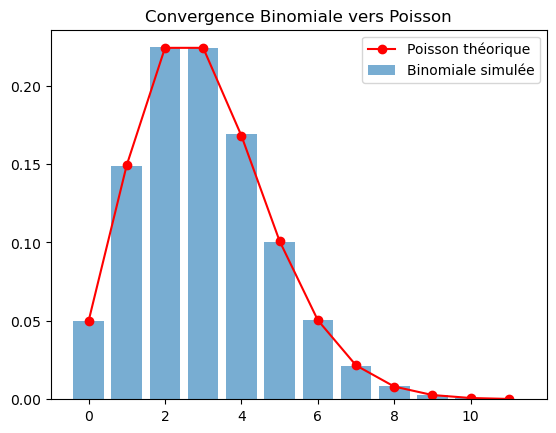

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
n=1000
p=0.003
lam=n*p
N=100000
x=np.random.binomial(n,p,size=N)
k=np.arange(0,12)
freq=[np.mean(x==i) for i in k]
plt.bar(k,freq,alpha=0.6,label="Binomiale simulée")
plt.plot(k,poisson.pmf(k,lam),"ro-",label="Poisson théorique")
plt.legend()
plt.title("Convergence Binomiale vers Poisson")
plt.show()


## Étude de convergence pour différentes valeurs de n

In [3]:
import numpy as np
from scipy.stats import binom, poisson
lam=3
for n in [20,50,100,500,1000]:
    p=lam/n
    err=sum(abs(binom.pmf(k,n,p)-poisson.pmf(k,lam)) for k in range(15))
    print(f"n={n}, erreur={err:.6f}")


n=20, erreur=0.080400
n=50, erreur=0.030844
n=100, erreur=0.015214
n=500, erreur=0.003010
n=1000, erreur=0.001503
